# Electride discovery with a reasoning swarm

Settings: `config.yaml`; the LLM is set up here in section 1 (it changes from system to system). Code: `agent.py` (schemas, prompts, swarm loop), `tools.py` (web, calculator, arXiv, local RAG), `evaluator.py` (deterministic evaluation of the agents' feature sets). This notebook only runs them.

Needs `electride_feature_rag_clean.jsonl` and the precomputed `electride_features_dataset.csv` in this folder; put extra PDFs in `inputs/kb/`.

In [1]:
%pip install -r src/requirements.txt

Note: you may need to restart the kernel to use updated packages.


## 1. LLM setup (system specific)

Endpoint, model, API key and call settings. `Swarm` only needs `llm` (an instructor client) and `MODEL_NAME`.

The setup below matches the README's LLM access example. Before running, replace `https://your-endpoint/v1` with your provider's actual API URL and set the `SN_API_KEY` environment variable to your API key.

In [21]:
import os, functools
import instructor
from openai import AsyncOpenAI

MODEL_NAME = "gpt-oss-120b"
client = AsyncOpenAI(base_url="https://your-endpoint/v1", api_key=os.environ["SN_API_KEY"])
async_gen = instructor.from_openai(client, mode=instructor.Mode.JSON)
# multi-attempt retrieval to guard against err response
TEMPERATURE = 0.7                                    # exploration level for every agent call
_create = functools.partial(async_gen.chat.completions.create, temperature=TEMPERATURE, max_retries=3, max_tokens=8192)
N_TRIES = 5
async def _create_with_retry(**kwargs):
    for attempt in range(N_TRIES):
        try:
            # retries step DOWN (0.7 -> 0.55 -> 0.4 -> 0.25 -> 0.1): lower temperature helps produce valid JSON
            return await _create(**kwargs, **({"temperature": max(0.1, TEMPERATURE - 0.15 * attempt)} if attempt else {}))
        except Exception as exc:
            if attempt == N_TRIES - 1:
                raise
            print(f"LLM call failed (attempt {attempt + 1}/{N_TRIES}: {type(exc).__name__}); retrying")
async_gen.chat.completions.create = _create_with_retry

print("Selected:", MODEL_NAME, "| temperature:", TEMPERATURE)

Selected: gpt-oss-120b | temperature: 0.7


## 2. Config

In [22]:
%load_ext autoreload
%autoreload 2

import sys; sys.path.insert(0, "src")
from agent import Swarm, load_config
from evaluator import score_dataset

CONFIG = load_config("config.yaml")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 3. Build the swarm

Uses the LLM from section 1; loads the embedding model, the feature data + evaluator, and the tools (builds the local paper index).

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

200 labeled structures (84 electrides), all used for evaluation; 26 of 49 catalog features usable; each proposal scored on 5 deterministic 60%/40% train/validation splits, stratified by class: every split trains on 50 electrides + 70 non-electrides and validates on 34 + 46
KB index: 227 chunks from 3 files in /Users/z8i/Desktop/LLM Hackathon/Github/ElectrideDetectives/inputs/kb
Discover an interpretable, physics-informed descriptor set that identifies electrides.
Electrides are ionic compounds in which some valence electrons are not bound to any atom but occupy
interstitial cavities, channels or layers and act as anions (anionic electrons). Using ONLY the precomputed
structural and chemical features of the labeled structures (catalog in the system prompt), find the set of features
whose combination separates electrides from non-electrides. Justify every selected feature physically, supported by
literature where possible. A model is fitted on your features and evaluated deterministicall

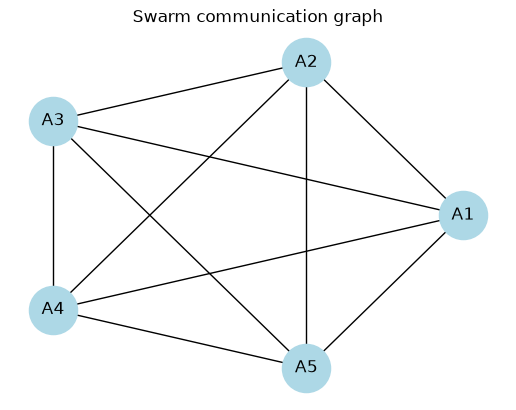

In [23]:
swarm = Swarm(CONFIG, llm=async_gen, model_name=MODEL_NAME)
swarm.plot_graph()

## 4. Run

Every round each agent may use one tool, then returns a `proposal` (the feature set its model should use). A gradient-boosting classifier is fitted on exactly those features and evaluated on all labeled structures over repeated stratified splits; the evaluation opens its next round. After the last round the top-ranked feature set is refit on all structures and the model is saved to `outputs/final_model_*.joblib`.

Run log: outputs/log_run_2026-10-22_143217.jsonl

==================== ROUND 1/5 ====================
finished: 

API call failed on attempt 1: Error code: 400 - {'error': 'Model did not output valid JSON.', 'error_code': None, 'error_model_output': '<|channel|>analysis<|message|>We need to propose first feature set. Need literature support: need to browse literature to justify selection. So first we should do literature_search for "electride descriptors cavity clearance". Let\'s request tool.<|end|><|start|>assistant<|channel|>final <|constrain|>tool":"literature_search","tool_input":"electride cavity clearance descriptors"}', 'error_param': None, 'error_type': 'Invalid structured output.'}
Max retries exceeded. Total attempts: 1, Last error: Error code: 400 - {'error': 'Model did not output valid JSON.', 'error_code': None, 'error_model_output': '<|channel|>analysis<|message|>We need to propose first feature set. Need literature support: need to browse literature to justify selection. So first we should do literature_search for "electride descriptors cavity clearance". Let\'s request tool.<|end|

LLM call failed (attempt 1/5: InstructorRetryException); retrying
A3 A2 A5 A4 A1 


Agent,Peers,Tool,Evidence,Feature set,Share of the model's decisions,F1,ROC-AUC,Electrides found / non-electrides rejected,Notes,Tokens in / out
A1,-,"literature_search ""electride screening descriptors cavity clearance electronegativity""",1812.06222 (2018): Discovering Inorganic Electrides from an Automated Computational Scree 1811.01169 (2018): Superconductivity in Li6P electride 2601.21077 (2026): Accelerated Inorganic Electrides Discovery by Generative Models and Hi,neutral_assignment_exists alkali_alkaline_site_fraction pauling_electronegativity__min max_clearance_A sampled_grid_clearance_statistics_A__mean volume_per_atom_A3,sampled_grid_clearance_statistics_A__mean 37% volume_per_atom_A3 23% max_clearance_A 16% alkali_alkaline_site_fraction 14% pauling_electronegativity__min 10% neutral_assignment_exists 1%,0.79 ± 0.05,0.90 ± 0.04,0.81 / 0.83,-,"8,770 / 2,298"
A2,-,"literature_search ""electride interstitial electron descriptors""",2605.11724 (2026): Theory and Discovery of Electrides 2512.02674 (2025): Rational regulation strategies of interstitial localized electrons in 2607.10024 (2026): Probing the Nature of Interstitial Anionic Electrons in 2D Electride C,alkali_alkaline_site_fraction pauling_electronegativity__min neutral_assignment_exists max_clearance_A sampled_grid_clearance_statistics_A__max metal_site_fraction,metal_site_fraction 31% pauling_electronegativity__min 23% max_clearance_A 20% sampled_grid_clearance_statistics_A__max 14% alkali_alkaline_site_fraction 11% neutral_assignment_exists 2%,0.78 ± 0.03,0.90 ± 0.02,0.83 / 0.78,-,"8,668 / 1,520"
A3,-,"literature_search ""electride descriptor cavity clearance electronegativity excess electrons""",2411.12170 (2024): Layered semiconducting electrides in p-block metal oxides 1811.01169 (2018): Superconductivity in Li6P electride 1812.06222 (2018): Discovering Inorganic Electrides from an Automated Computational Scree,alkali_alkaline_site_fraction pauling_electronegativity__min max_clearance_A sampled_grid_clearance_statistics_A__max neutral_assignment_exists,pauling_electronegativity__min 36% max_clearance_A 28% sampled_grid_clearance_statistics_A__max 20% alkali_alkaline_site_fraction 13% neutral_assignment_exists 3%,0.71 ± 0.04,0.86 ± 0.03,0.73 / 0.77,-,"8,813 / 1,795"
A4,-,"literature_search ""electride interstitial electron descriptors""",2605.11724 (2026): Theory and Discovery of Electrides 2512.02674 (2025): Rational regulation strategies of interstitial localized electrons in 2607.10024 (2026): Probing the Nature of Interstitial Anionic Electrons in 2D Electride C,alkali_alkaline_site_fraction pauling_electronegativity__min max_clearance_A volume_per_atom_A3 total_assignment_count neutral_assignment_exists,volume_per_atom_A3 29% pauling_electronegativity__min 22% max_clearance_A 22% total_assignment_count 15% alkali_alkaline_site_fraction 10% neutral_assignment_exists 1%,0.72 ± 0.04,0.84 ± 0.03,0.75 / 0.75,-,"12,571 / 1,545"
A5,-,"literature_search ""electride cavity clearance descriptors""",2605.11724 (2026): Theory and Discovery of Electrides 1812.06222 (2018): Discovering Inorganic Electrides from an Automated Computational Scree 2603.06212 (2026): Topological descriptors of foot clearance gait dynamics improve differ,alkali_alkaline_site_fraction pauling_electronegativity__min neutral_assignment_exists max_clearance_A sampled_grid_clearance_statistics_A__mean candidate_count_before_output_limit,sampled_grid_clearance_statistics_A__mean 37% max_clearance_A 18% alkali_alkaline_site_fraction 16% candidate_count_before_output_limit 14% pauling_electronegativity__min 12% neutral_assignment_exists 2%,0.78 ± 0.03,0.90 ± 0.02,0.79 / 0.83,-,"8,652 / 1,502"


Agent,Answer,Next step,Suggested new features
A1,"The screening studies of Zhu et al. (2018) identify three physical ingredients that separate electrides from ordinary ionic crystals: (i) the presence of excess valence electrons that cannot be assigned to a charge‑balanced oxidation‑state configuration, (ii) a lattice populated by strongly electropositive elements (low Pauling electronegativity and high alkali/alkaline‑earth content), and (iii) interstitial cavities large enough to host an anion ...","Await the deterministic evaluation of this initial feature set. Based on the ROC‑AUC and feature importance scores, I will decide whether to reinforce the cavity descriptors (e.g., add sampled_grid_clearance_statistics_A__max) or replace less informa","• void_connectivity_dimension: categorical metric (0D,1D,2D) describing the dimensionality of the interconnected void network. • ELF_max_interstitial: maximum value of the electron localisation function in identified void regions. • interstitial_band_energy: energy of the lowest interstitial‑derived electronic band relative to the Fermi level."
A2,"The recent review ""Theory and Discovery of Electrides"" (arXiv:2605.11724) emphasizes three physical ingredients that distinguish electrides: (i) the presence of highly electropositive cations (alkali/alkaline‑earth), (ii) a low electronegativity environment that leaves excess valence electrons unbound, and (iii) sufficiently large interstitial voids that can host anionic electrons. The authors also note that many electrides cannot be assigned a c ...","Await the deterministic evaluation of the proposed descriptor set on the 200‑structure benchmark. Based on the ROC‑AUC and feature importance scores, I will refine the set—e.g., replace redundant cavity metrics, add statistical descriptors of clearan","• statistical aggregation (e.g., mean) of sampled_grid_clearance_statistics_A to capture overall void abundance • distribution of electron localization function (ELF) maxima in interstitial regions • computed excess electron count per formula unit from DFT"
A3,"The literature confirms that electrides are distinguished by (i) highly electropositive cations (low Pauling electronegativity, especially the minimum value across sites), (ii) a substantial fraction of alkali or alkaline‑earth elements, (iii) large interstitial voids that can accommodate anionic electrons (large clearance values), and (iv) a charge‑imbalanced oxidation‑state assignment, i.e., the absence of a neutral oxidation‑state combination. ...","After the deterministic evaluation of this feature set, I will examine which descriptors contribute most to ROC‑AUC and whether any class (e.g., electrides with small cavities) is still mis‑classified. If needed, I will consider adding volume_per_ato","• statistical measure of electronegativity spread (e.g., pauling_electronegativity__std) to capture contrast between electropositive cations and more electronegat • volume_per_atom_A3 as a proxy for overall lattice openness, which may aid in distinguishing low‑density frameworks that host interstitial electrons"
A4,"The recent review \[arXiv:2605.11724\] emphasizes three physical ingredients for electride classification: (i) the presence of strongly electropositive cations that donate excess electrons, (ii) a low overall electronegativity that discourages electron binding to atoms, and (iii) sufficiently large interstitial cavities that can accommodate anionic electrons. Accordingly, I propose a descriptor set that directly measures these aspects using the a ...","After receiving the deterministic ROC‑AUC evaluation of this initial set, I will analyse which features contribute most (e.g., via feature importance) and consider adding complementary descriptors such as the standard deviation of cavity clearance or",• Standard deviation of sampled_grid_clearance_statistics_A (cavity size heterogeneity) • Fraction of transition_metal_site_fraction (to penalize structures where transition meta

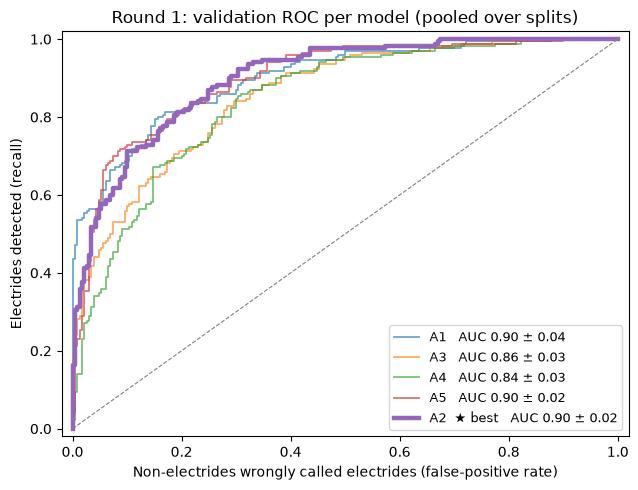

Best feature set in round 1: A2 | ROC-AUC 0.90 ± 0.02 | F1 0.78 ± 0.03 | metal_site_fraction  31%, pauling_electronegativity__min  23%, max_clearance_A  20%, sampled_grid_clearance_statistics_A__max  14%, alkali_alkaline_site_fraction  11%, neutral_assignment_exists  2%

==================== ROUND 2/5 ====================
finished: A1 A5 A2 A4 A3 


Agent,Peers,Tool,Evidence,Feature set,Share of the model's decisions,F1,ROC-AUC,Electrides found / non-electrides rejected,Notes,Tokens in / out
A1,"A2, A4","literature_search ""electride cavity clearance heterogeneity transition metal suppression""",2106.00921 (2021): Anomalous diamagnetism of electride electrons in transition metal sili 2411.12170 (2024): Layered semiconducting electrides in p-block metal oxides 1811.01169 (2018): Superconductivity in Li6P electride,alkali_alkaline_site_fraction pauling_electronegativity__min max_clearance_A sampled_grid_clearance_statistics_A__std volume_per_atom_A3 candidate_count_before_output_limit,volume_per_atom_A3 26% pauling_electronegativity__min 20% candidate_count_before_output_limit 20% sampled_grid_clearance_statistics_A__std 12% alkali_alkaline_site_fraction 11% max_clearance_A 11%,0.76 ± 0.02,0.87 ± 0.04,0.78 / 0.80,chose no tool; asked to gather evidence worse vs parent #5 (-0.030),"34,553 / 5,080"
A2,"A1, A4","literature_search ""electride transition metal cavity clearance""",2106.00921 (2021): Anomalous diamagnetism of electride electrons in transition metal sili 2411.12170 (2024): Layered semiconducting electrides in p-block metal oxides 1811.01169 (2018): Superconductivity in Li6P electride,alkali_alkaline_site_fraction pauling_electronegativity__min max_clearance_A sampled_grid_clearance_statistics_A__mean sampled_grid_clearance_statistics_A__std metal_site_fraction,sampled_grid_clearance_statistics_A__mean 34% metal_site_fraction 19% alkali_alkaline_site_fraction 14% max_clearance_A 14% sampled_grid_clearance_statistics_A__std 11% pauling_electronegativity__min 9%,0.84 ± 0.04,0.94 ± 0.03,0.86 / 0.87,chose no tool; asked to gather evidence improved vs parent #2 (+0.032),"34,150 / 4,568"
A3,"A1, A4","literature_search ""electride volume per atom void space""",2302.06999 (2023): Superconductivity in Li8Au electride 2411.12170 (2024): Layered semiconducting electrides in p-block metal oxides 1603.04161 (2016): Inverse Design of Inorganic Electrides,alkali_alkaline_site_fraction pauling_electronegativity__min max_clearance_A sampled_grid_clearance_statistics_A__mean volume_per_atom_A3 total_assignment_count,sampled_grid_clearance_statistics_A__mean 35% volume_per_atom_A3 21% total_assignment_count 18% alkali_alkaline_site_fraction 10% max_clearance_A 9% pauling_electronegativity__min 7%,0.78 ± 0.03,0.90 ± 0.03,0.81 / 0.80,chose no tool; asked to gather evidence improved vs parent #1 (+0.040),"33,965 / 3,849"
A4,"A1, A3","literature_search ""electride electronegativity spread f-block""",1811.01169 (2018): Superconductivity in Li6P electride 2411.12170 (2024): Layered semiconducting electrides in p-block metal oxides 2409.17249 (2024): Semiconducting Electrides Derived From Sodalite: A First-principles St,alkali_alkaline_site_fraction pauling_electronegativity__min pauling_electronegativity__std max_clearance_A sampled_grid_clearance_statistics_A__mean volume_per_atom_A3 total_assignment_count f_block_site_fraction,sampled_grid_clearance_statistics_A__mean 28% volume_per_atom_A3 17% total_assignment_count 15% pauling_electronegativity__std 12% alkali_alkaline_site_fraction 12% f_block_site_fraction 7% max_clearance_A 5% pauling_electronegativity__min 5%,0.82 ± 0.04,0.93 ± 0.04,0.85 / 0.83,chose no tool; asked to gather evidence improved vs parent #4 (+0.083),"34,053 / 4,779"
A5,"A4, A1","literature_search ""electride transition metal fraction""",2106.00921 (2021): Anomalous diamagnetism of electride electrons in transition metal sili 2411.12170 (2024): Layered semiconducting electrides in p-block metal oxides 1811.01169 (2018): Superconductivity in Li6P electride,alkali_alkaline_site_fraction pauling_electronegativity__min max_clearance_A sampled_grid_clearance_statistics_A__mean sampled_grid_clearance_statistics_A__std transition_metal_site_fraction f_block_site_fraction,sampled_grid_clearance_statistics_A__mean 24% alkali_alkaline_site_fraction 18% f_block_site_fraction 14% 

Agent,Answer,Next step,Suggested new features
A1,"The new literature (arXiv:2106.00921) shows that transition‑metal silicides can host electride electrons in interstitial sites, indicating that the mere presence of transition metals does not preclude electride formation. Consequently, the transition_metal_site_fraction is not a reliable discriminator and should be removed. The evaluation of the previous model also revealed that the binary oxidation‑state flag contributed almost nothing and that ...","Run the deterministic evaluation of the revised six‑feature set. If ROC‑AUC improves, consider further refinements such as adding a second cavity heterogeneity metric (sampled_grid_clearance_statistics_A__max) or exploring non‑linear interactions. If","• void_connectivity_dimension: categorical metric (0D,1D,2D) describing the dimensionality of the interconnected void network. • ELF_max_interstitial: maximum value of the electron localisation function in identified void regions. • interstitial_band_energy: energy of the lowest interstitial‑derived electronic band relative to the Fermi level."
A2,"The recent study of transition‑metal silicide electrides (LaScSi, Y5Si3) shows that the presence of transition‑metal atoms does not exclude electride behavior; rather, the key factors remain (i) a high proportion of electropositive s‑block cations, (ii) a low minimum Pauling electronegativity, (iii) sufficiently large interstitial voids, and (iv) an overall metallic framework that can host delocalised electrons. The evaluation of my Round‑1 set c ...","Await the deterministic evaluation of the revised six‑feature set. If the ROC‑AUC does not improve, I will consider adding the total_assignment_count (oxidation‑state combinatorial richness) or a cavity‑size heterogeneity metric (std) as a replacemen",• total_assignment_count (number of possible oxidation‑state assignments) to capture excess‑electron combinatorial richness • ELF_max_interstitial (maximum electron localisation function value in identified voids) • interstitial_band_energy (energy of the lowest interstitial‑derived electronic band relative to the Fermi level)
A3,"The new literature confirms that electride stability is linked to (i) highly symmetric, cage‑like frameworks that provide large interstitial voids (Li8Au electride, Li8 cages) and (ii) excess interstitial electrons that arise when many oxidation‑state combinations exist but no neutral assignment can be made. These observations justify using a bulk‑scale openness metric (volume_per_atom_A3) as a proxy for cage‑like void abundance, and swapping the ...","Await the deterministic evaluation of the proposed feature set. If ROC‑AUC improves, consider adding a measure of electronegativity spread (pauling_electronegativity__std) to capture contrast between electropositive cations and more electronegative a",• pauling_electronegativity__std – to capture the contrast between electropositive cations and more electronegative anions • cavity_geometry.sampled_grid_clearance_statistics_A__std – to quantify heterogeneity of void sizes • metal_site_fraction – to penalize structures dominated by transition metals that may trap electrons
A4,"The literature confirms two key chemical cues for electrides: (i) the presence of very electropositive cations (e.g., Li in Li6P) combined with relatively low‑electronegativity anions, and (ii) that a larger contrast between the most electropositive and more electronegative elements promotes electron localisation in interstitial sites (the Li6P study emphasizes ""weak electronegativity of P with a strong electropositivity of Li""). The p‑block elec ...",I will await the deterministic ROC‑AUC evaluation of the new eight‑feature set. Based on the resulting feature‑importance scores I will decide whether to keep both cavity‑size metrics or replace one with a more discriminating void‑heterogeneity descr,"• sampled_grid_clearance_statistics_A__std (heterogeneity of void sizes) • metal_site_fraction (ove

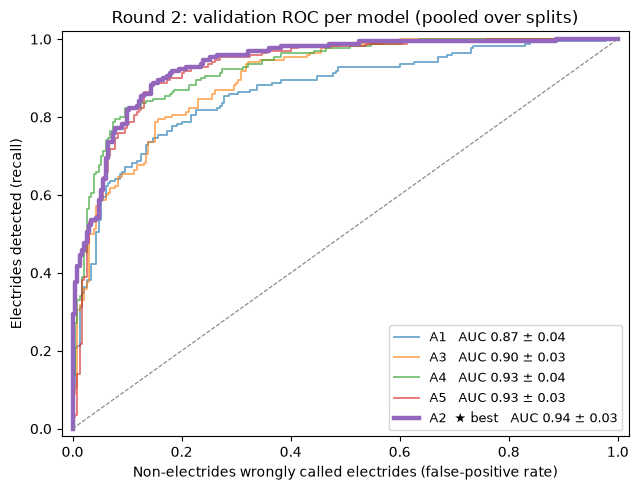

Best feature set in round 2: A2 | ROC-AUC 0.94 ± 0.03 | F1 0.84 ± 0.04 | sampled_grid_clearance_statistics_A__mean  34%, metal_site_fraction  19%, alkali_alkaline_site_fraction  14%, max_clearance_A  14%, sampled_grid_clearance_statistics_A__std  11%, pauling_electronegativity__min  9%

==================== ROUND 3/5 ====================
finished: A3 A4 A5 A1 A2 


Agent,Peers,Tool,Evidence,Feature set,Share of the model's decisions,F1,ROC-AUC,Electrides found / non-electrides rejected,Notes,Tokens in / out
A1,"A4, A3","literature_search ""electride electronegativity spread""",1811.01169 (2018): Superconductivity in Li6P electride 2411.12170 (2024): Layered semiconducting electrides in p-block metal oxides 2409.17249 (2024): Semiconducting Electrides Derived From Sodalite: A First-principles St,alkali_alkaline_site_fraction pauling_electronegativity__min pauling_electronegativity__std max_clearance_A sampled_grid_clearance_statistics_A__mean volume_per_atom_A3 total_assignment_count f_block_site_fraction,sampled_grid_clearance_statistics_A__mean 28% volume_per_atom_A3 17% total_assignment_count 15% pauling_electronegativity__std 12% alkali_alkaline_site_fraction 12% f_block_site_fraction 7% max_clearance_A 5% pauling_electronegativity__min 5%,0.82 ± 0.04,0.93 ± 0.04,0.85 / 0.83,chose no tool; asked to gather evidence same model as #9 improved vs parent #5 (+0.029),"55,502 / 4,067"
A2,"A4, A3","literature_search ""electride electronegativity spread""",1811.01169 (2018): Superconductivity in Li6P electride 2411.12170 (2024): Layered semiconducting electrides in p-block metal oxides 2409.17249 (2024): Semiconducting Electrides Derived From Sodalite: A First-principles St,alkali_alkaline_site_fraction pauling_electronegativity__min pauling_electronegativity__std max_clearance_A sampled_grid_clearance_statistics_A__mean sampled_grid_clearance_statistics_A__std metal_site_fraction,sampled_grid_clearance_statistics_A__mean 30% pauling_electronegativity__std 16% metal_site_fraction 15% alkali_alkaline_site_fraction 14% max_clearance_A 13% pauling_electronegativity__min 6% sampled_grid_clearance_statistics_A__std 6%,0.84 ± 0.05,0.94 ± 0.03,0.86 / 0.86,chose no tool; asked to gather evidence improved vs parent #8 (+0.008),"55,095 / 4,021"
A3,"A4, A1","literature_search ""electride electronegativity spread cavity heterogeneity""",1811.01169 (2018): Superconductivity in Li6P electride 2411.12170 (2024): Layered semiconducting electrides in p-block metal oxides 2409.17249 (2024): Semiconducting Electrides Derived From Sodalite: A First-principles St,alkali_alkaline_site_fraction pauling_electronegativity__std sampled_grid_clearance_statistics_A__mean sampled_grid_clearance_statistics_A__std volume_per_atom_A3 total_assignment_count candidate_count_before_output_limit,sampled_grid_clearance_statistics_A__mean 32% volume_per_atom_A3 19% total_assignment_count 16% pauling_electronegativity__std 12% alkali_alkaline_site_fraction 11% candidate_count_before_output_limit 6% sampled_grid_clearance_statistics_A__std 5%,0.82 ± 0.04,0.92 ± 0.04,0.85 / 0.83,chose no tool; asked to gather evidence improved vs parent #10 (+0.016),"55,960 / 4,759"
A4,"A1, A3","literature_search ""electride void candidate count descriptor""",2605.11724 (2026): Theory and Discovery of Electrides 2508.04548 (2025): Using Topology to Predict Electrides in the Solid State 1603.04161 (2016): Inverse Design of Inorganic Electrides,alkali_alkaline_site_fraction pauling_electronegativity__min volume_per_atom_A3 total_assignment_count sampled_grid_clearance_statistics_A__mean sampled_grid_clearance_statistics_A__std candidate_count_before_output_limit,sampled_grid_clearance_statistics_A__mean 33% volume_per_atom_A3 21% total_assignment_count 17% alkali_alkaline_site_fraction 9% candidate_count_before_output_limit 7% sampled_grid_clearance_statistics_A__std 7% pauling_electronegativity__min 6%,0.80 ± 0.02,0.91 ± 0.03,0.84 / 0.81,chose no tool; asked to gather evidence worse vs parent #9 (-0.017),"56,791 / 5,171"
A5,"A4, A3","literature_search ""electride electronegativity spread""",1811.01169 (2018): Superconductivity in Li6P electride 2411.12170 (2024): Layered semiconducting electrides in p-block metal oxides 2409.17249 (2024): Semiconducting Electrides Derived From Sodalite: A First-principles St,alkali_alkaline_site_fraction pauling_elect

Agent,Answer,Next step,Suggested new features
A1,"The abstracts of Li6P (arXiv:1811.01169) and the sodalite‑derived electride study (arXiv:2409.17249) both emphasize that a *large contrast* between a very electropositive cation (Li) and a relatively more electronegative anion (P) drives interstitial electron localisation. This supports using the *standard deviation of Pauling electronegativities* (pauling_electronegativity__std) as a quantitative proxy for that contrast. Moreover, the review (ar ...","Submit the eight‑feature set for deterministic evaluation. If ROC‑AUC improves over the previous best (0.897), consider further refinements such as adding a heterogeneity metric for cavity clearances (sampled_grid_clearance_statistics_A__std) or a vo","• sampled_grid_clearance_statistics_A__std – heterogeneity of void sizes, to capture the presence of both tight and spacious interstitial regions. • void_connectivity_dimension – categorical metric (0D,1D,2D) describing the dimensionality of the interconnected void network. • ELF_max_interstitial – maximum value of the electron localisation function in identified void regions."
A2,"The abstracts retrieved confirm that a contrast between very electropositive and more electronegative elements is a key driver of interstitial electron localisation. Li6P is described as a combination of a weakly electronegative P and strongly electropositive Li, while the sodalite‑derived electride study explicitly states that “a lower electronegativity of surrounding cations drives greater electron localisation”. The layered SnO/PbO electrides ...","Submit the seven‑feature set for deterministic evaluation. If ROC‑AUC does not improve, consider replacing the highly correlated sampled_grid_clearance_statistics_A__std with total_assignment_count (oxidation‑state richness) or removing metal_site_fr",• total_assignment_count (number of viable oxidation‑state assignments) to capture excess‑electron combinatorial richness • ELF_max_interstitial (maximum electron localisation function value in identified voids) • interstitial_band_energy (energy of the lowest interstitial‑derived band relative to the Fermi level)
A3,"The deterministic evaluation of the previous six‑feature set showed that the minimum Pauling electronegativity and the single‑value max_clearance_A contribute little, likely because their information is already captured by other descriptors. The literature now provides two concrete physical insights: (i) Li6P electride performance is attributed to a *weak electronegativity of the anion (P) combined with a strong electropositivity of Li* (arXiv:18 ...","Submit the revised seven‑feature set for deterministic evaluation. If ROC‑AUC improves, consider testing whether adding a penalty for f‑block chemistry (f_block_site_fraction) further refines the model, or whether a non‑linear interaction between EN‑","• void_connectivity_dimension – categorical metric (0D,1D,2D) describing the dimensionality of the interconnected void network. • ELF_max_interstitial – maximum electron localisation function value in identified void regions. • interstitial_band_energy – energy of the lowest interstitial‑derived electronic band relative to the Fermi level."
A4,The recent descriptor‑development study (arXiv:2605.11724) explicitly proposes using geometric metrics of interstitial space – such as the number of void‑center candidates and clearance statistics – as high‑throughput descriptors for electride discovery. This supports keeping the scalar feature *candidate_count_before_output_limit* as a proxy for how many accessible interstitial sites a crystal provides. The same work also stresses the importan ...,"Run the deterministic evaluation of the new seven‑feature set. If ROC‑AUC improves, consider adding a void‑connectivity proxy (e.g., candidate_count_before_output_limit normalized by volume) or an ELF‑based descriptor in future rounds.","• void_connectivity_dimension – categorical metric (0D, 1D, 2D) describing the 

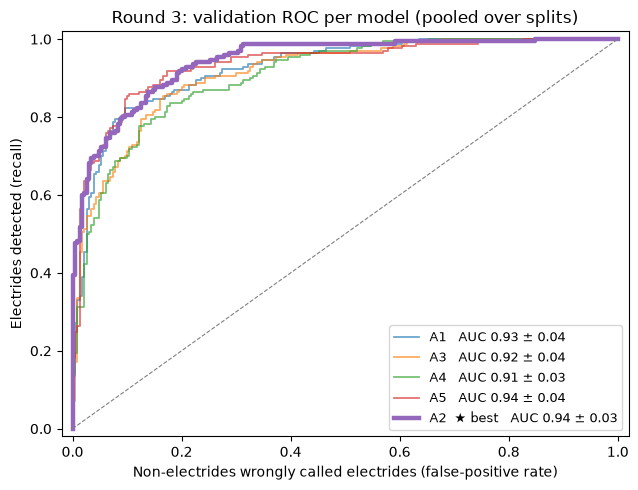

Best feature set in round 3: A2 | ROC-AUC 0.94 ± 0.03 | F1 0.84 ± 0.05 | sampled_grid_clearance_statistics_A__mean  30%, pauling_electronegativity__std  16%, metal_site_fraction  15%, alkali_alkaline_site_fraction  14%, max_clearance_A  13%, pauling_electronegativity__min  6%, sampled_grid_clearance_statistics_A__std  6%

==================== ROUND 4/5 ====================
finished: A1 A5 A2 A3 A4 


Agent,Peers,Tool,Evidence,Feature set,Share of the model's decisions,F1,ROC-AUC,Electrides found / non-electrides rejected,Notes,Tokens in / out
A1,"A4, A2",-,-,alkali_alkaline_site_fraction pauling_electronegativity__min volume_per_atom_A3 total_assignment_count sampled_grid_clearance_statistics_A__mean candidate_count_before_output_limit metal_site_fraction,sampled_grid_clearance_statistics_A__mean 29% volume_per_atom_A3 19% total_assignment_count 18% metal_site_fraction 11% alkali_alkaline_site_fraction 9% candidate_count_before_output_limit 8% pauling_electronegativity__min 6%,0.79 ± 0.03,0.91 ± 0.04,0.82 / 0.81,worse vs parent #14 (-0.016),"26,051 / 1,538"
A2,"A4, A1",-,-,alkali_alkaline_site_fraction pauling_electronegativity__std sampled_grid_clearance_statistics_A__mean volume_per_atom_A3 total_assignment_count candidate_count_before_output_limit metal_site_fraction,sampled_grid_clearance_statistics_A__mean 28% volume_per_atom_A3 17% total_assignment_count 16% pauling_electronegativity__std 12% alkali_alkaline_site_fraction 10% metal_site_fraction 9% candidate_count_before_output_limit 7%,0.82 ± 0.04,0.93 ± 0.04,0.84 / 0.85,no clear change vs parent #15 (-0.014),"25,923 / 1,779"
A3,"A4, A2",-,-,alkali_alkaline_site_fraction pauling_electronegativity__min max_clearance_A sampled_grid_clearance_statistics_A__mean volume_per_atom_A3 total_assignment_count metal_site_fraction,sampled_grid_clearance_statistics_A__mean 32% volume_per_atom_A3 18% total_assignment_count 18% metal_site_fraction 11% alkali_alkaline_site_fraction 8% max_clearance_A 7% pauling_electronegativity__min 6%,0.80 ± 0.05,0.92 ± 0.03,0.83 / 0.82,no clear change vs parent #11 (+0.003),"25,899 / 1,503"
A4,"A3, A2",-,-,alkali_alkaline_site_fraction pauling_electronegativity__std volume_per_atom_A3 total_assignment_count sampled_grid_clearance_statistics_A__mean sampled_grid_clearance_statistics_A__std metal_site_fraction,sampled_grid_clearance_statistics_A__mean 31% volume_per_atom_A3 17% total_assignment_count 16% pauling_electronegativity__std 12% alkali_alkaline_site_fraction 10% metal_site_fraction 9% sampled_grid_clearance_statistics_A__std 5%,0.82 ± 0.05,0.92 ± 0.03,0.85 / 0.83,no clear change vs parent #9 (-0.008),"26,068 / 1,657"
A5,"A4, A2",-,-,alkali_alkaline_site_fraction pauling_electronegativity__min volume_per_atom_A3 sampled_grid_clearance_statistics_A__mean total_assignment_count candidate_count_before_output_limit transition_metal_site_fraction metal_site_fraction,sampled_grid_clearance_statistics_A__mean 28% volume_per_atom_A3 18% total_assignment_count 18% metal_site_fraction 11% alkali_alkaline_site_fraction 9% candidate_count_before_output_limit 7% pauling_electronegativity__min 5% transition_metal_site_fraction 4%,0.82 ± 0.04,0.91 ± 0.04,0.85 / 0.83,worse vs parent #13 (-0.024),"26,141 / 1,708"


Agent,Answer,Next step,Suggested new features
A1,"The latest evaluation shows that the binary oxidation‑state flag and several cavity descriptors (max_clearance_A, pauling_electronegativity__std, f_block_site_fraction) contribute little and are highly correlated with other features. The most informative descriptors are the mean sampled clearance, the normalized cell volume, the alkali/alkaline‑earth fraction, and the total oxidation‑state assignment count. To capture the richness of the intersti ...","Submit the revised seven‑feature set for deterministic evaluation. If ROC‑AUC improves, consider further refinements such as normalising candidate_count_before_output_limit by volume_per_atom_A3 or adding a heterogeneity metric for void clearances (s","• sampled_grid_clearance_statistics_A__std – heterogeneity of void sizes, to capture the presence of both tight and spacious interstitial regions. • void_connectivity_dimension – categorical metric (0D,1D,2D) describing the dimensionality of the interconnected void network. • ELF_max_interstitial – maximum value of the electron localisation function within identified void regions."
A2,"The evaluation of the previous seven‑feature set showed that (i) the minimum Pauling electronegativity and the clearance‑standard‑deviation contributed little, (ii) max_clearance_A is almost perfectly correlated with the mean clearance, and (iii) the model still lacks a direct proxy for the combinatorial excess‑electron condition and for the richness of the void network. The literature supports adding two new descriptors: (a) total_assignment_cou ...","Submit the revised seven‑feature set for deterministic evaluation. If ROC‑AUC does not improve, consider normalising candidate_count_before_output_limit by volume_per_atom_A3 to capture void density, or re‑introducing max_clearance_A if the mean clea",• total_assignment_count (already used here) – retained for excess‑electron quantification • ELF_max_interstitial – maximum electron localisation function value within identified void regions (currently unavailable) • interstitial_band_energy – energy of the lowest interstitial‑derived electronic band relative to the Fermi level (currently unavailable)
A3,"The latest evaluation shows that the electronegativity‑standard‑deviation, clearance‑standard‑deviation and candidate‑count features contribute little and are highly correlated with other descriptors. The literature repeatedly stresses (i) a very low minimum Pauling electronegativity (Li6P, sodalite electride) as a strong indicator of excess electrons, (ii) the absolute size of the largest cavity (max_clearance_A) for accommodating anionic electr ...","Submit the revised seven‑feature set for deterministic evaluation. If the ROC‑AUC improves, further refinements could explore a derived metric such as candidate_count_before_output_limit / volume_per_atom_A3 to capture void density, or incorporate th","• void_connectivity_dimension – categorical metric (0D, 1D, 2D) describing the dimensionality of the interconnected void network. • ELF_max_interstitial – maximum electron localisation function value within identified void regions. • interstitial_band_energy – energy of the lowest interstitial‑derived electronic band relative to the Fermi level."
A4,"The latest evaluation shows that the minimum electronegativity and the raw candidate count add little predictive power, while the spread of electronegativities, the heterogeneity of interstitial clearances, and the presence of a metallic framework are not yet fully exploited. Literature (Li6P, sodalite electrides, transition‑metal silicides) highlights three physical pillars: (i) a strongly electropositive chemistry with a large donor‑acceptor el ...","Submit the proposed seven‑feature set for deterministic evaluation. If ROC‑AUC improves, consider testing a non‑linear interaction term between electronegativity spread and clearance heterogeneity, or adding a void‑connectivity proxy (e.g., candidate","• void_con

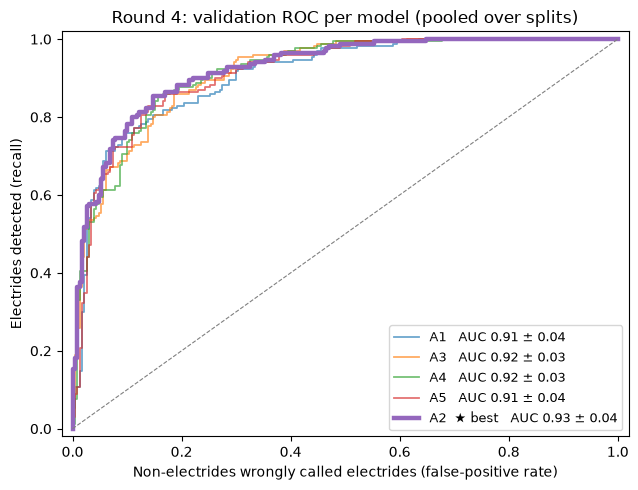

Best feature set in round 4: A2 | ROC-AUC 0.93 ± 0.04 | F1 0.82 ± 0.04 | sampled_grid_clearance_statistics_A__mean  28%, volume_per_atom_A3  17%, total_assignment_count  16%, pauling_electronegativity__std  12%, alkali_alkaline_site_fraction  10%, metal_site_fraction  9%, candidate_count_before_output_limit  7%

==================== ROUND 5/5 ====================
finished: A1 A4 A2 A5 A3 


Agent,Peers,Tool,Evidence,Feature set,Share of the model's decisions,F1,ROC-AUC,Electrides found / non-electrides rejected,Notes,Tokens in / out
A1,"A4, A2",-,-,alkali_alkaline_site_fraction pauling_electronegativity__std volume_per_atom_A3 total_assignment_count sampled_grid_clearance_statistics_A__mean sampled_grid_clearance_statistics_A__std metal_site_fraction,sampled_grid_clearance_statistics_A__mean 31% volume_per_atom_A3 17% total_assignment_count 16% pauling_electronegativity__std 12% alkali_alkaline_site_fraction 10% metal_site_fraction 9% sampled_grid_clearance_statistics_A__std 5%,0.82 ± 0.05,0.92 ± 0.03,0.85 / 0.83,same model as #20 no clear change vs parent #14 (-0.008),"29,439 / 1,548"
A2,"A4, A1",-,-,alkali_alkaline_site_fraction pauling_electronegativity__min pauling_electronegativity__std max_clearance_A sampled_grid_clearance_statistics_A__mean metal_site_fraction total_assignment_count,sampled_grid_clearance_statistics_A__mean 31% total_assignment_count 17% pauling_electronegativity__std 14% metal_site_fraction 14% alkali_alkaline_site_fraction 10% max_clearance_A 9% pauling_electronegativity__min 6%,0.84 ± 0.05,0.95 ± 0.03,0.88 / 0.85,improved vs parent #15 (+0.006),"30,041 / 1,801"
A3,"A2, A4",-,-,alkali_alkaline_site_fraction pauling_electronegativity__min pauling_electronegativity__max volume_per_atom_A3 total_assignment_count sampled_grid_clearance_statistics_A__mean candidate_count_before_output_limit metal_site_fraction,sampled_grid_clearance_statistics_A__mean 28% total_assignment_count 18% volume_per_atom_A3 17% metal_site_fraction 10% alkali_alkaline_site_fraction 8% candidate_count_before_output_limit 7% pauling_electronegativity__max 6% pauling_electronegativity__min 5%,0.80 ± 0.03,0.92 ± 0.04,0.83 / 0.83,worse vs parent #19 (-0.002),"29,977 / 1,835"
A4,"A2, A1",-,-,alkali_alkaline_site_fraction pauling_electronegativity__min volume_per_atom_A3 total_assignment_count sampled_grid_clearance_statistics_A__mean candidate_count_before_output_limit metal_site_fraction f_block_site_fraction,sampled_grid_clearance_statistics_A__mean 25% total_assignment_count 18% volume_per_atom_A3 17% metal_site_fraction 11% alkali_alkaline_site_fraction 9% candidate_count_before_output_limit 8% f_block_site_fraction 8% pauling_electronegativity__min 5%,0.81 ± 0.03,0.91 ± 0.04,0.84 / 0.83,worse vs parent #9 (-0.012),"30,287 / 1,734"
A5,"A4, A1",-,-,alkali_alkaline_site_fraction pauling_electronegativity__min pauling_electronegativity__std volume_per_atom_A3 sampled_grid_clearance_statistics_A__mean total_assignment_count transition_metal_site_fraction metal_site_fraction,sampled_grid_clearance_statistics_A__mean 29% total_assignment_count 16% volume_per_atom_A3 16% pauling_electronegativity__std 12% alkali_alkaline_site_fraction 9% metal_site_fraction 8% pauling_electronegativity__min 5% transition_metal_site_fraction 4%,0.81 ± 0.05,0.91 ± 0.04,0.87 / 0.80,worse vs parent #13 (-0.022),"30,279 / 1,927"


Agent,Answer,Next step,Suggested new features
A1,"The latest evaluation indicates that the features most strongly separating electrides are (i) a high fraction of electropositive alkali/alkaline‑earth sites, (ii) a large spread of elemental electronegativities (high EN standard deviation) which creates a strong donor‑acceptor contrast, (iii) overall lattice openness (high volume per atom), (iv) a low number of charge‑balanced oxidation‑state assignments (excess‑electron indicator), (v) spacious ...","Submit the seven‑feature set for deterministic evaluation. If ROC‑AUC improves beyond 0.94, explore normalising the candidate void count by volume_per_atom_A3 to capture void density, or add a derived metric for void‑connectivity dimension.","• sampled_grid_clearance_statistics_A__std – heterogeneity of void sizes (already used here but could be combined with a normalised version). • void_connectivity_dimension – categorical metric (0D, 1D, 2D) describing the dimensionality of the interconnected void network. • ELF_max_interstitial – maximum electron localisation function value within identified void regions (requires additional electronic‑structure data)."
A2,"The round‑3 best set achieved ROC‑AUC 0.944 by combining electropositivity (alkali_alkaline_site_fraction), low minimum electronegativity, electronegativity spread, and several cavity descriptors (max_clearance_A, mean and std of sampled clearances) together with metal_site_fraction. Feature‑importance analysis shows that the most decisive contributors are the alkali fraction, the minimum EN, the max/mean clearance and metal_site_fraction, while ...","Submit the revised seven‑feature set for deterministic evaluation. If ROC‑AUC improves, consider testing an interaction term between electronegativity spread and mean clearance, or normalising candidate_count_before_output_limit by volume_per_atom_A3","• candidate_count_before_output_limit (raw count of void‑center candidates) – to capture void‑network richness if further improvement is needed. • void_connectivity_dimension – categorical metric (0D,1D,2D) describing the dimensionality of the interconnected void network. • ELF_max_interstitial – maximum electron localisation function value within identified void regions."
A3,"The latest evaluation shows that the minimum Pauling electronegativity and the single‑value max_clearance_A contribute little, likely because their information is already captured by other descriptors. The literature repeatedly stresses (i) a very low minimum electronegativity of the most electropositive cations (Li6P, sodalite electride) as a hallmark of excess electrons, (ii) the presence of highly electronegative anions that create a strong do ...","Submit the revised seven‑feature set for deterministic evaluation. If ROC‑AUC improves, consider a derived void‑density metric (candidate_count_before_output_limit / volume_per_atom_A3) as a suggested new feature in a future round, or explore non‑lin","• void_connectivity_dimension – categorical metric (0D,1D,2D) describing the dimensionality of the interconnected void network. • ELF_max_interstitial – maximum electron localisation function value within identified void regions. • interstitial_band_energy – energy of the lowest interstitial‑derived electronic band relative to the Fermi level."
A4,"The latest deterministic evaluation shows that the electronegativity‑standard‑deviation and clearance‑standard‑deviation contribute little and are highly correlated with other descriptors. Literature (Li6P, sodalite electrides, transition‑metal silicide electrides) emphasizes three pillars: (i) a strongly electropositive chemistry with a low minimum electronegativity, (ii) an excess‑electron condition captured by a low number of charge‑balanced o ...","Submit the proposed seven‑feature set for deterministic evaluation. If ROC‑AUC improves, I will consider normalising candidate_count_before_output_limit by volume_per_atom_A3 to capture void density, or re‑introducing

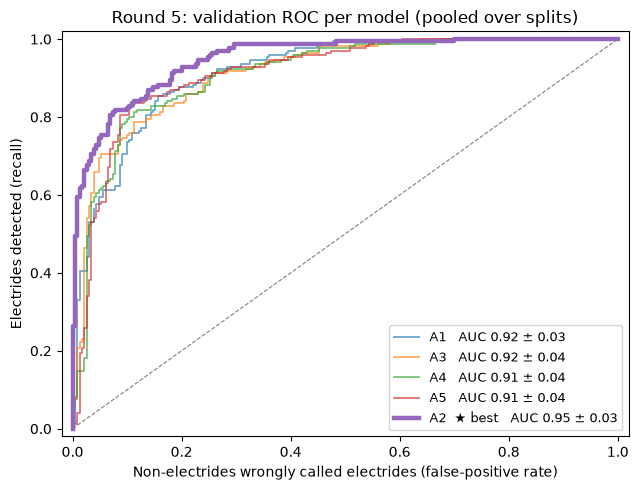

Best feature set in round 5: A2 | ROC-AUC 0.95 ± 0.03 | F1 0.84 ± 0.05 | sampled_grid_clearance_statistics_A__mean  31%, total_assignment_count  17%, pauling_electronegativity__std  14%, metal_site_fraction  14%, alkali_alkaline_site_fraction  10%, max_clearance_A  9%, pauling_electronegativity__min  6%


Rank,,#,Agent,Round,Features,F1,ROC-AUC,Electrides found / non-electrides rejected,Feature set (share of the model's decisions)
1,★,23,A2,5,7,0.84 ± 0.05,0.95 ± 0.03,0.88 / 0.85,sampled_grid_clearance_statistics_A__mean 31% total_assignment_count 17% pauling_electronegativity__std 14% metal_site_fraction 14% alkali_alkaline_site_fraction 10% max_clearance_A 9% pauling_electronegativity__min 6%
2,,15,A2,3,7,0.84 ± 0.05,0.94 ± 0.03,0.86 / 0.86,sampled_grid_clearance_statistics_A__mean 30% pauling_electronegativity__std 16% metal_site_fraction 15% alkali_alkaline_site_fraction 14% max_clearance_A 13% pauling_electronegativity__min 6% sampled_grid_clearance_statistics_A__std 6%
3,,13,A5,3,8,0.85 ± 0.05,0.94 ± 0.04,0.86 / 0.87,sampled_grid_clearance_statistics_A__mean 26% volume_per_atom_A3 17% alkali_alkaline_site_fraction 17% pauling_electronegativity__std 13% transition_metal_site_fraction 8% f_block_site_fraction 7% max_clearance_A 6% sampled_grid_clearance_statistics_A__std 6%
4,,8,A2,2,6,0.84 ± 0.04,0.94 ± 0.03,0.86 / 0.87,sampled_grid_clearance_statistics_A__mean 34% metal_site_fraction 19% alkali_alkaline_site_fraction 14% max_clearance_A 14% sampled_grid_clearance_statistics_A__std 11% pauling_electronegativity__min 9%
5,,18,A2,4,7,0.82 ± 0.04,0.93 ± 0.04,0.84 / 0.85,sampled_grid_clearance_statistics_A__mean 28% volume_per_atom_A3 17% total_assignment_count 16% pauling_electronegativity__std 12% alkali_alkaline_site_fraction 10% metal_site_fraction 9% candidate_count_before_output_limit 7%
6,,7,A5,2,7,0.85 ± 0.02,0.93 ± 0.03,0.89 / 0.85,sampled_grid_clearance_statistics_A__mean 24% alkali_alkaline_site_fraction 18% f_block_site_fraction 14% transition_metal_site_fraction 13% sampled_grid_clearance_statistics_A__std 11% max_clearance_A 10% pauling_electronegativity__min 9%
7,,9,A4,2,8,0.82 ± 0.04,0.93 ± 0.04,0.85 / 0.83,sampled_grid_clearance_statistics_A__mean 28% volume_per_atom_A3 17% total_assignment_count 15% pauling_electronegativity__std 12% alkali_alkaline_site_fraction 12% f_block_site_fraction 7% max_clearance_A 5% pauling_electronegativity__min 5%
8,,19,A3,4,7,0.80 ± 0.05,0.92 ± 0.03,0.83 / 0.82,sampled_grid_clearance_statistics_A__mean 32% volume_per_atom_A3 18% total_assignment_count 18% metal_site_fraction 11% alkali_alkaline_site_fraction 8% max_clearance_A 7% pauling_electronegativity__min 6%


Item,Value
Model,"#23 (A2, round 5)"
Ranked first by,highest validation ROC-AUC (mean over 5 splits)
Fitted on all 200 structures,"gradient boosting on 7 features (n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.9)"
cavity_geometry.sampled_grid_clearance_statistics_A__mean,share of the model's decisions 28%
structure_summary.metal_site_fraction,share of the model's decisions 18%
electron_count_hypotheses.total_assignment_count,share of the model's decisions 17%
cavity_geometry.max_clearance_A,share of the model's decisions 13%
structure_summary.alkali_alkaline_site_fraction,share of the model's decisions 12%
structure_summary.pauling_electronegativity__std,share of the model's decisions 10%
structure_summary.pauling_electronegativity__min,share of the model's decisions 4%


Suggested new feature,Times suggested,"By (agent, round)",Description (first seen)
ELF_max_interstitial,19,"A1 R1, A1 R2, A5 R2, A2 R2, A3 R3, A4 R3, A5 R3, A1 R3, A2 R3, A1 R4, A5 R4, A2 R4, A3 R4, A4 R4, A1 R5, A4 R5, A2 R5, A5 R5, A3 R5",ELF_max_interstitial: maximum value of the electron localisation function in identified void regions.
void_connectivity_dimension,16,"A1 R1, A1 R2, A5 R2, A3 R3, A4 R3, A5 R3, A1 R3, A1 R4, A5 R4, A3 R4, A4 R4, A1 R5, A4 R5, A2 R5, A5 R5, A3 R5","void_connectivity_dimension: categorical metric (0D,1D,2D) describing the dimensionality of the interconnected void network."
interstitial_band_energy,15,"A1 R1, A1 R2, A5 R2, A2 R2, A3 R3, A4 R3, A5 R3, A2 R3, A5 R4, A2 R4, A3 R4, A4 R4, A4 R5, A5 R5, A3 R5",interstitial_band_energy: energy of the lowest interstitial‑derived electronic band relative to the Fermi level.
sampled_grid_clearance_statistics_A__std,4,"A4 R2, A1 R3, A1 R4, A1 R5",sampled_grid_clearance_statistics_A__std (heterogeneity of void sizes)
total_assignment_count,3,"A2 R2, A2 R3, A2 R4",total_assignment_count (number of possible oxidation‑state assignments) to capture excess‑electron combinatorial richness
metal_site_fraction,2,"A4 R2, A3 R2","metal_site_fraction (overall metallic character, could help differentiate metallic electrides from non‑metallic conductors)"
candidate_count_before_output_limit,1,A2 R5,candidate_count_before_output_limit (raw count of void‑center candidates) – to capture void‑network richness if further improvement is needed.
cavity_geometry.sampled_grid_clearance_statistics_A__std,1,A3 R2,cavity_geometry.sampled_grid_clearance_statistics_A__std – to quantify heterogeneity of void sizes
computed excess electron count per formula unit from DFT,1,A2 R1,computed excess electron count per formula unit from DFT
distribution of electron localization function,1,A2 R1,distribution of electron localization function (ELF) maxima in interstitial regions


Agent,calls,prompt,completion,reasoning
A1,10,154315,14531,4035
A2,10,153877,13689,4650
A3,10,154614,13741,4088
A4,11,159770,14886,5002
A5,10,156248,14046,3898
TOTAL,51,778824,70893,21673


In [24]:
last_round, results = await swarm.run()

## 5. Analysis of the run

All plots come from the evaluations the swarm already did (`swarm.evaluator.history`), so nothing is refitted.

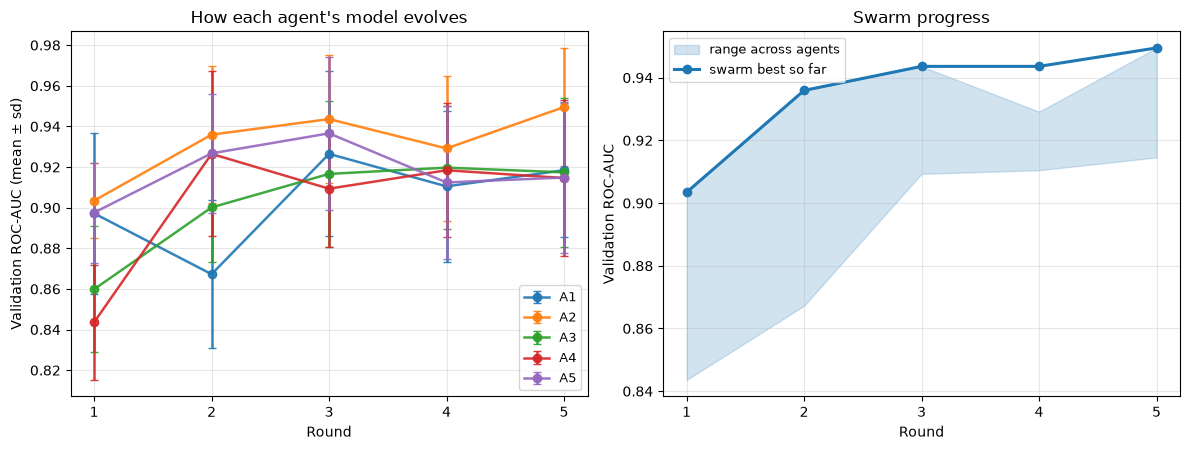

,Agent,Round,Features,roc_auc,± sd,vs parent
0,A1,1,6,0.897,0.040,first
1,A1,2,6,0.867,0.036,worse
2,A1,3,8,0.926,0.041,improved
3,A1,4,7,0.910,0.037,worse
4,A1,5,7,0.918,0.033,no clear change
5,A2,1,6,0.903,0.018,first
6,A2,2,6,0.936,0.034,improved
7,A2,3,7,0.944,0.032,improved
8,A2,4,7,0.929,0.036,no clear change
9,A2,5,7,0.949,0.029,improved


In [25]:
import analysis

# How each agent's score evolves, and the swarm's best-so-far
progress = analysis.plot_agent_progress(swarm)
progress

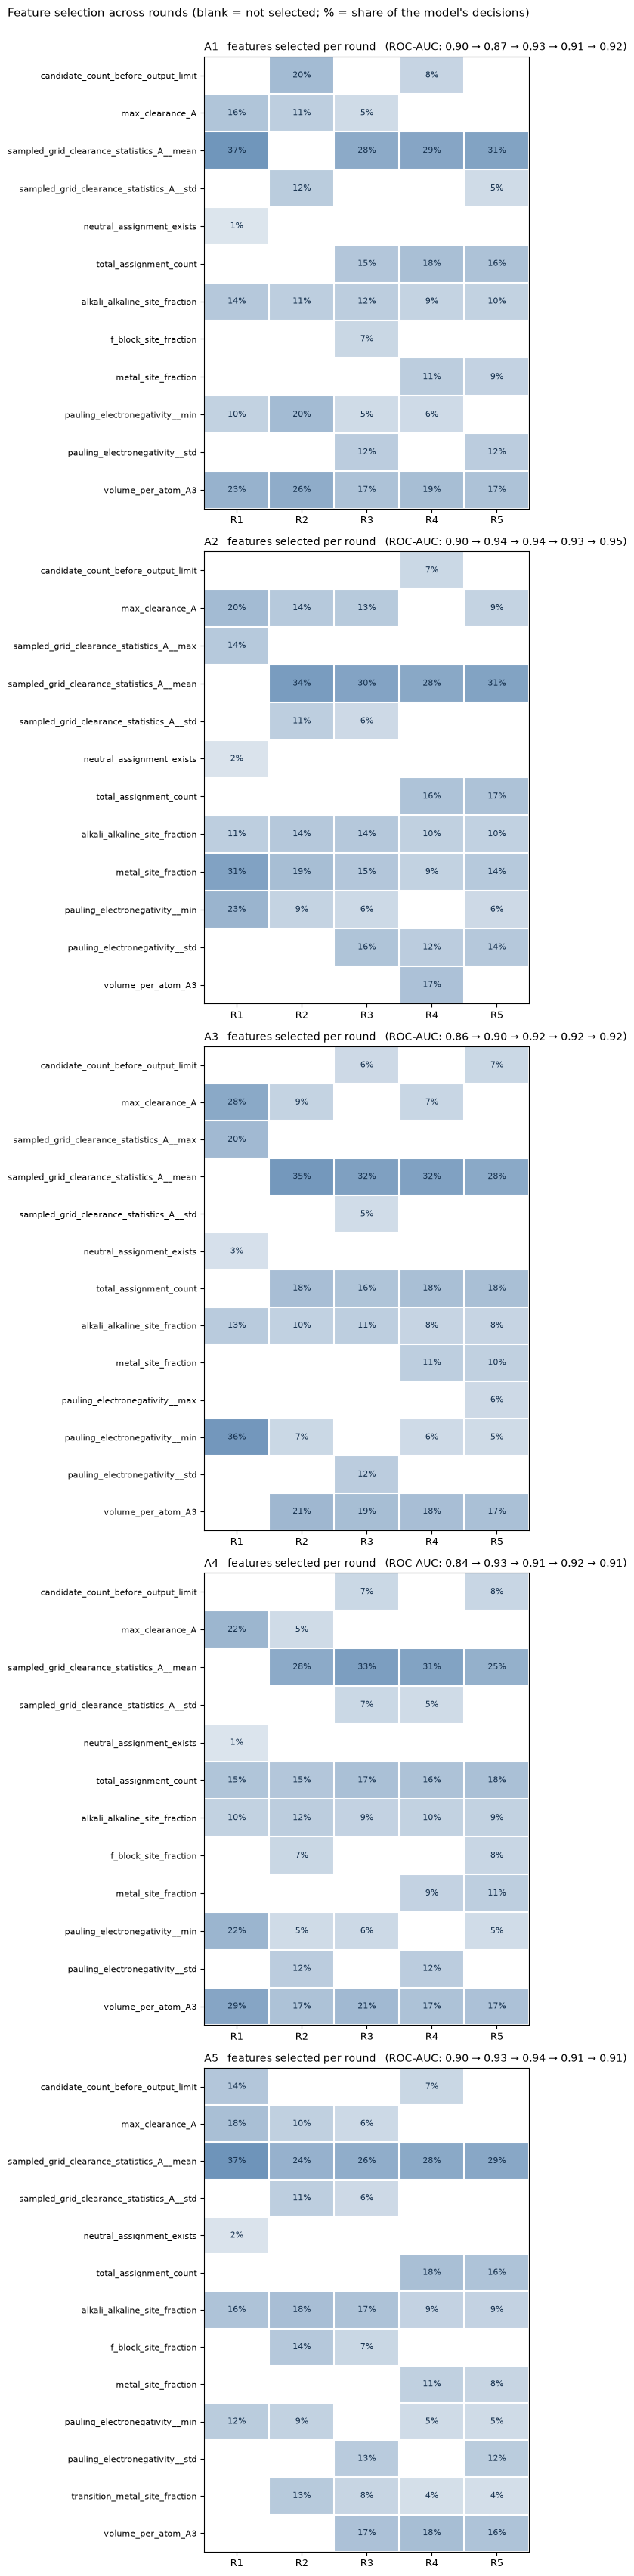

In [26]:
# Which features each agent selected in each round (% = share of that round's fitted model decisions)
analysis.plot_feature_map(swarm)

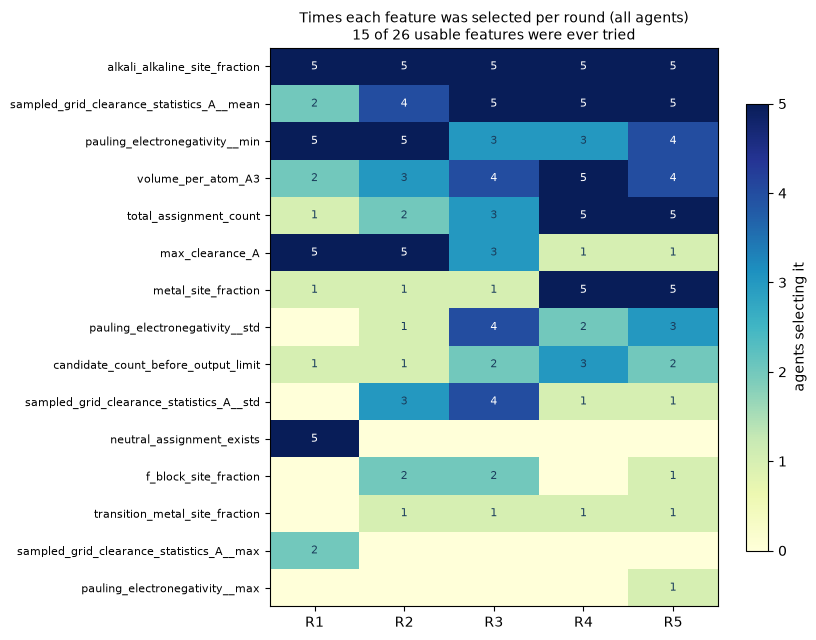

In [27]:
# How often each feature was selected per round, across all agents
analysis.plot_feature_usage(swarm)

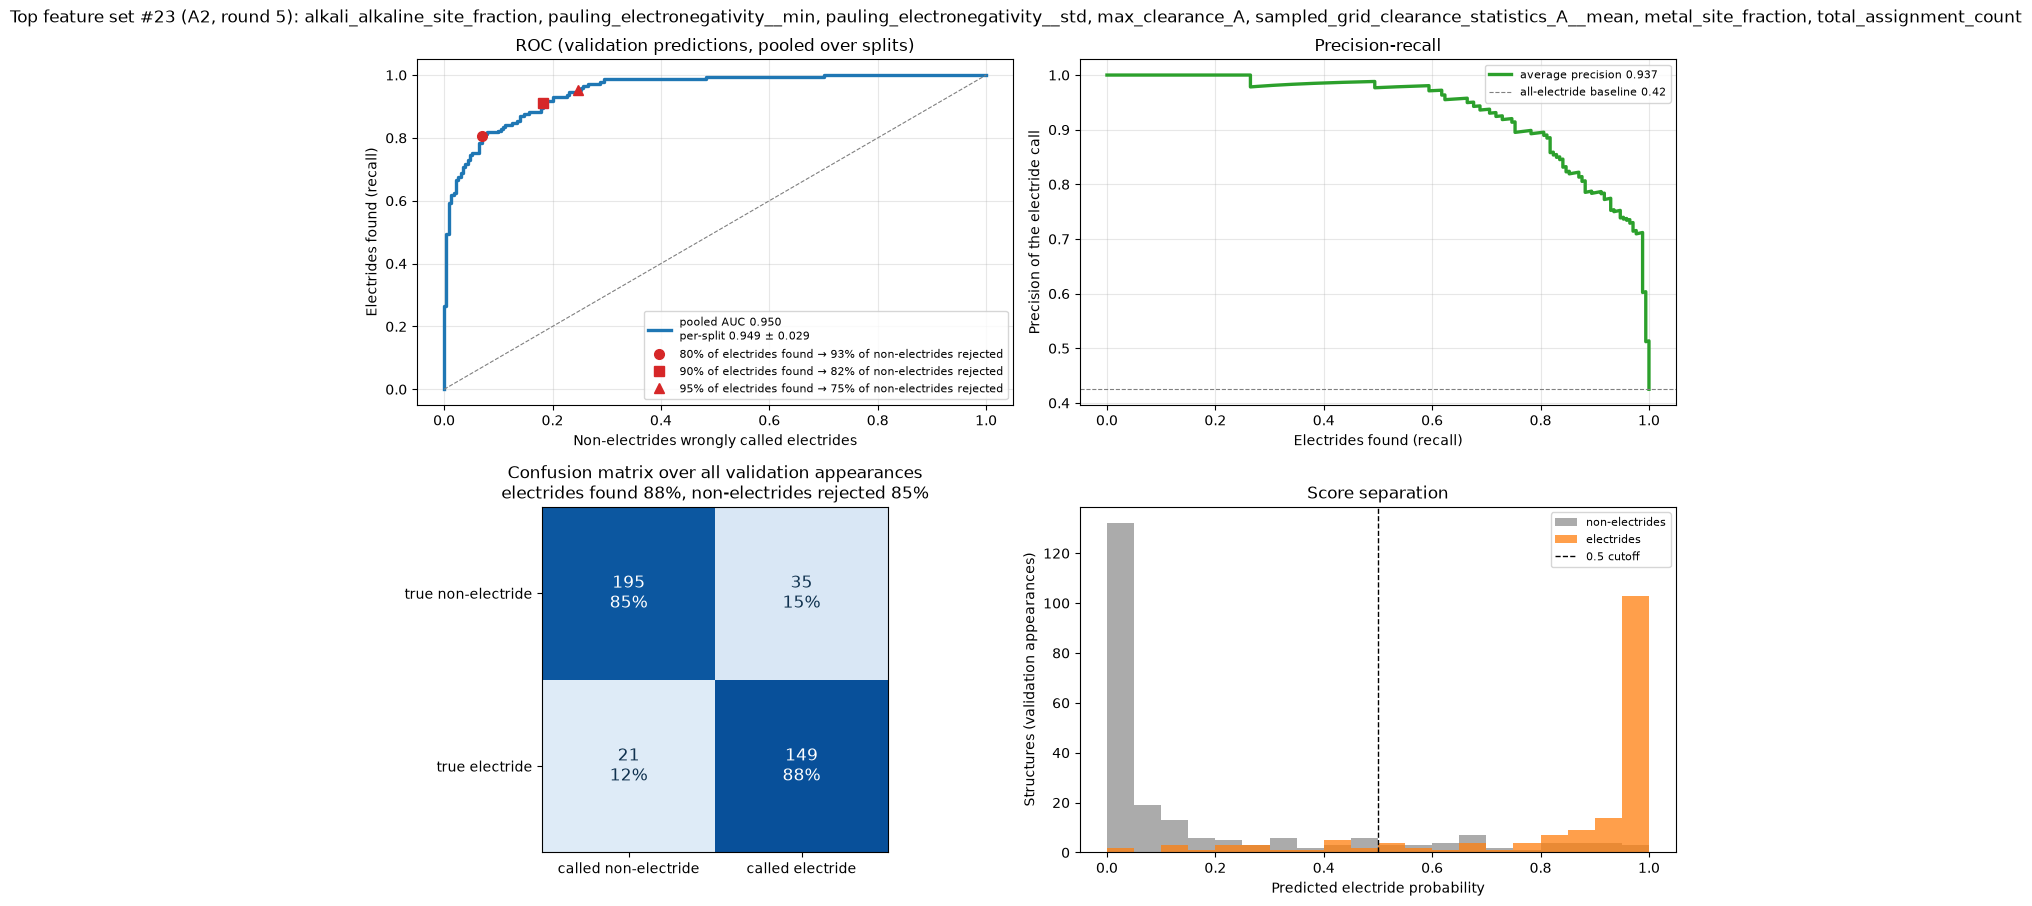

,Metric,Mean over splits,± sd
0,roc auc,0.949,0.029
1,f1,0.841,0.051
2,accuracy,0.860,0.042
3,precision,0.809,0.035
4,recall,0.876,0.073
5,specificity,0.848,0.024


In [28]:
# Classification metrics of the top-ranked feature set (validation predictions pooled over the splits)
metrics = analysis.plot_final_model(swarm, results)
metrics

## 6. Structure viewer

Pass the CIF paths of one electride and one non-electride. `pick_example_structures` finds the most confidently predicted example of each class and its CIF under `cif_dir`; otherwise give the two paths yourself. Use `repeat=(2, 2, 1)` to tile the cell and `rotations=` for other orientations.

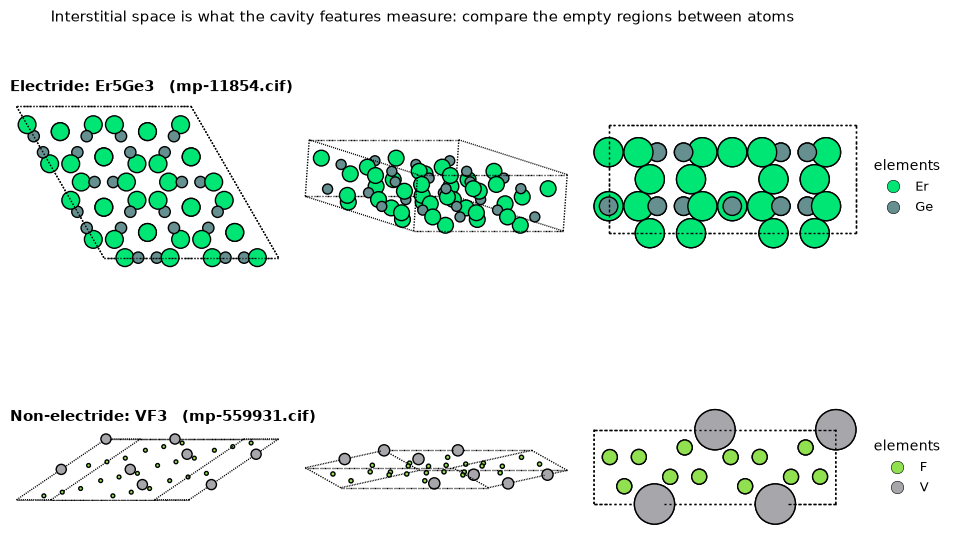

In [29]:
# Option A: let the top model pick the clearest example of each class (needs CIFs in cif_dir)
# el_cif, non_cif, probability = analysis.pick_example_structures(swarm, results, cif_dir="structures")

# Option B: your own two files
el_cif, non_cif, probability = "data/data_extract/structures/mp-11854.cif", "data/data_extract/structures/mp-559931.cif", None

analysis.show_structures(el_cif, non_cif, repeat=(2, 2, 1), probability=probability)

## 7. Score a dataset with the final model

Swap `DATA_CSV` for your separate dataset (labels optional). In a new session use `score_dataset(None, ...)` for the newest `outputs/final_model_*.joblib`, or pass its path.

In [30]:
DATA_CSV = CONFIG["data"]["dataset_csv"]
scores, score_metrics = score_dataset(results["final_fit"], DATA_CSV, out_csv="outputs/final_model_scores.csv")
scores.sort_values("probability", ascending=False)

Model from outputs/final_model_2026-10-22_143217.joblib:
  features: structure_summary.alkali_alkaline_site_fraction, structure_summary.pauling_electronegativity__min, structure_summary.pauling_electronegativity__std, cavity_geometry.max_clearance_A, cavity_geometry.sampled_grid_clearance_statistics_A__mean, structure_summary.metal_site_fraction, electron_count_hypotheses.total_assignment_count
  electron_count_hypotheses__total_assignment_count: 7 missing -> training median 4
Metrics: {'n': 200, 'electrides': 84, 'accuracy': 1.0, 'precision': 1.0, 'recall': 1.0, 'specificity': 1.0, 'f1': 1.0, 'roc_auc': 1.0}
Confusion matrix [[TN, FP], [FN, TP]]: [[116, 0], [0, 84]]
Saved 200 scores to outputs/final_model_scores.csv


/Users/z8i/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(


,structure,probability,predicted,label
197,mp-9909.cif,0.996991,1,1
88,mp-1189366.cif,0.996561,1,1
118,mp-1245.cif,0.996289,1,1
135,mp-17124.cif,0.996146,1,1
132,mp-1464.cif,0.995389,1,1
...,...,...,...,...
193,mp-975665.cif,0.001879,0,0
76,mp-1180981.cif,0.001794,0,0
44,matpes-20240214_78_0.cif,0.001794,0,0
75,mp-1180947.cif,0.001688,0,0
